# CodeContests-O concise-response rerun

**Result.** After one round of self-training, held-out passes increased from **8/60 to 12/60**. Four problems improved and none regressed. The adapted model completed fewer responses and its completed responses were longer. The verifier picked the sole passing solution in four of five informative held-out pairs, a promising observation with a small denominator.

The model produced code followed by a short explanation under a **1,024-token output cap**. Training used a **1,792-token total sequence limit**, including the prompt. One rank-8 QLoRA adapter trained for one epoch on self-selected responses. Execution results were recorded independently. Passing means passing every **recorded** case for that problem.

In [1]:
from pathlib import Path
import json
from math import comb
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

here = Path.cwd()
root = here / 'results'

def load(run):
    def read(name):
        return pd.read_json(run/f'{name}.jsonl', lines=True, dtype={'id': str})
    cfg = json.loads((run/'manifest.json').read_text(encoding='utf-8'))
    tasks = json.loads((run/'problems.json').read_text(encoding='utf-8'))
    data = (read('candidates').merge(read('judgments')[['id','score','accepted']], on='id',
                                   how='left', validate='one_to_one')
            .merge(read('execution')[['id','outcome']], on='id', how='left', validate='one_to_one'))
    pairs = pd.read_csv(run/'paired_results.csv')
    source = {t['id']: t.get('source_split','test') for t in tasks['test']}
    pairs['source'] = pairs.problem.map(source)
    return cfg, data, pairs

cfg, data, pairs = load(root)
display(pd.Series({key:cfg[key] for key in ('dataset','model','seed','train_count','test_count','cap','sequence_limit','threshold')}, name='Setting').to_frame())
display(pairs.source.value_counts().rename('Held-out problems').to_frame())

,Setting
dataset,caijanfeng/CodeContests-O
model,mistralai/Ministral-3-3B-Reasoning-2512
seed,42
train_count,40
test_count,60
cap,1024
sequence_limit,1792
threshold,0.5


,Held-out problems
source,
train,33
test,27


### Training selection and audit

The judge saw each candidate's code and explanation. Its score is the softmax weight for accept over the two verdict tokens. A candidate entered training if its score exceeded 0.5, it provided complete code, and its full prompt and response fit the training limit.

The fair random baseline draws **38** from the **same format- and length-eligible pool**. The judge selected 8 passing programs, versus about 6.4 expected from random selection. This is modest enrichment. Most selected responses still failed the execution audit. The audit evaluates final code behaviour and leaves the reasoning trace unlabelled.

,Candidates,Passes,Pass rate (%)
Group,,,
Generated,80,10,12.5
Scored,61,10,16.4
Training-eligible before threshold,59,10,16.9
Selected,38,8,21.1


Uniform random selection of 38 eligible candidates: 6.44 expected passes.


accepted,Excluded,Selected
outcome,,
invalid_response,19,0
pass,2,8
runtime_error,6,3
timeout,2,0
wrong_output,13,27


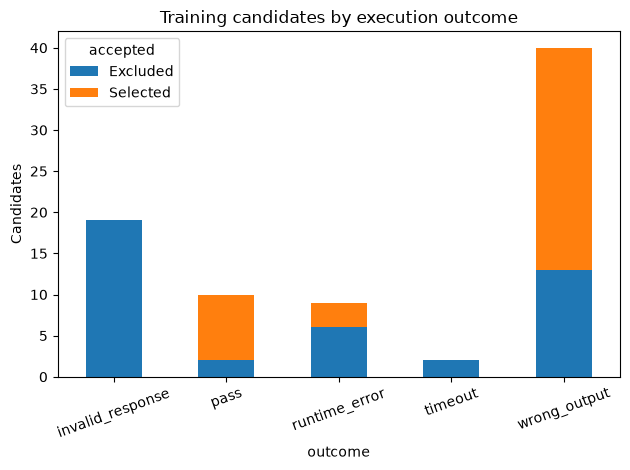

In [2]:
def selection(data, cfg):
    train = data[data.id.str.startswith('train-')]
    eligible = train[train.score.notna() & train.complete & train.program.notna()
                     & train.ids.map(len).le(cfg['sequence_limit'])]
    selected = train[train.accepted.eq(True)]
    return train, eligible, selected

train, eligible, selected = selection(data, cfg)
groups = {'Generated': train, 'Scored': train[train.score.notna()],
          'Training-eligible before threshold': eligible, 'Selected': selected}
display(pd.DataFrame([{'Group': name, 'Candidates': len(g), 'Passes': g.outcome.eq('pass').sum(),
                       'Pass rate (%)': 100*g.outcome.eq('pass').mean()}
                      for name,g in groups.items()]).set_index('Group').round(1))
expected = len(selected)*eligible.outcome.eq('pass').mean()
print(f'Uniform random selection of {len(selected)} eligible candidates: {expected:.2f} expected passes.')
table = pd.crosstab(train.outcome, train.accepted.eq(True).map({True:'Selected',False:'Excluded'}))
display(table)
table.plot.bar(stacked=True, rot=20, title='Training candidates by execution outcome', ylabel='Candidates')
plt.tight_layout()
plt.show()

### Can the judge pick the better program?

This comparison ranks two original-model responses to the same problem. It includes a pair when both responses received scores and execution outcomes. Uniform random choice gets one expected pass if both programs pass, half if exactly one passes, and zero if neither passes. Score ties receive random-choice credit.

The judge picked **10 passing programs**, versus **8.5 expected** across **38 scorable pairs**. It picked the passing program in **4 of the 5 mixed pairs**. The other 33 pairs could not distinguish ranking quality because both candidates had the same binary outcome. This supports a small observed gain over random choice, with limited evidence about generalization. A one-sided exact binomial calculation for 4 of 5 gives p = 0.188 under independent fair choices. The score measures the usefulness of ranking generated candidates. It does not establish that verification is intrinsically easier than generation.

,Judge passes,Random expected passes,Pairs
All scorable,10.0,8.5,38
Mixed only,4.0,2.5,5


,problem,source,original_0,score_0,original_1,score_1,judge
6,test-006,test,wrong_output,0.321,pass,0.755,1.0
27,test-027,train,runtime_error,0.893,pass,0.852,0.0
37,test-037,train,runtime_error,0.294,pass,0.755,1.0
41,test-041,train,runtime_error,0.119,pass,0.378,1.0
46,test-046,train,timeout,0.706,pass,0.818,1.0


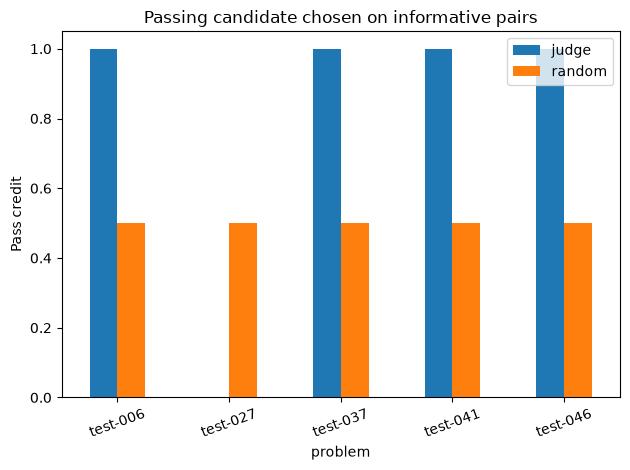

In [3]:
def ranking(pairs):
    usable = pairs.dropna(subset=['score_0','score_1','original_0','original_1'])
    usable = usable[~usable[['original_0','original_1']].eq('infrastructure_error').any(axis=1)].copy()
    a, b = usable.original_0.eq('pass'), usable.original_1.eq('pass')
    random = (a.astype(float)+b.astype(float))/2
    judge = a.where(usable.score_0.ge(usable.score_1), b).astype(float)
    usable['judge'] = judge.where(usable.score_0.ne(usable.score_1), random)
    usable['random'] = random
    usable['mixed'] = a.ne(b)
    return usable

rank = ranking(pairs)
mixed = rank[rank.mixed]
display(pd.DataFrame({'Judge passes':[rank.judge.sum(),mixed.judge.sum()],
                      'Random expected passes':[rank.random.sum(),mixed.random.sum()],
                      'Pairs':[len(rank),len(mixed)]}, index=['All scorable','Mixed only']))
display(mixed[['problem','source','original_0','score_0','original_1','score_1','judge']].round(3))
mixed[['judge','random']].set_index(mixed.problem).plot.bar(
    title='Passing candidate chosen on informative pairs', ylabel='Pass credit', rot=20)
plt.tight_layout()
plt.show()

### Adapter training

The main training log records **38 updates**, one per selected response. Prompt tokens served as context and were masked in the loss. The plotted loss measures fit to the response tokens at each update. The updates use different examples, so the curve is descriptive. Functional performance comes from held-out execution.

,Value
Updates,38.000
Median loss,0.171
Training minutes,1.222


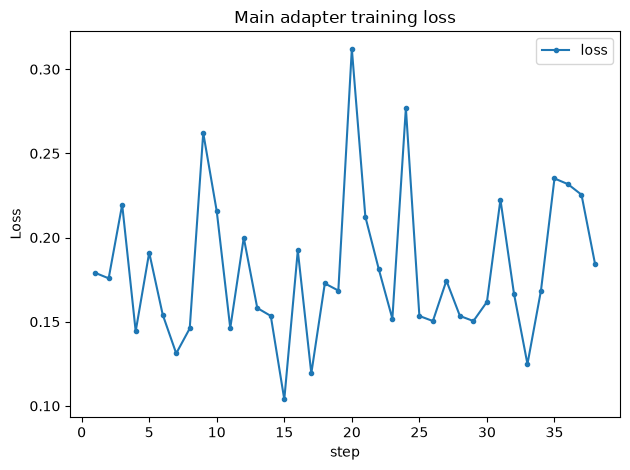

In [4]:
logs = [p for p in root.glob('training-*.jsonl') if not p.name.startswith('training-probe-')]
loss = pd.read_json(max(logs,key=lambda p:p.stat().st_mtime),lines=True)
display(pd.Series({'Updates':len(loss),'Median loss':loss.loss.median(),
                   'Training minutes':loss.seconds.sum()/60},name='Value').round(3).to_frame())
loss.assign(step=range(1,len(loss)+1)).plot(x='step',y='loss',marker='.',
                                         title='Main adapter training loss',ylabel='Loss')
plt.tight_layout()
plt.show()

### Held-out results and response length

Each pair compares the first original-model response with one adapted response for the same problem. Both used the same prompt, seed, sampling settings, cap, and execution cases. The primary result is **13.3% to 20.0%**, a gain of **6.7 percentage points**. Four problems improved and none regressed. The exact two-sided paired test uses only those four changes and gives **p = 0.125**.

The adapter provided extractable programs on **41/60** tasks versus **45/60** for the original. On the **36 tasks where both produced programs**, passes rose from **8 to 11**. This subset describes changes when both outputs were testable. Since inclusion depends on both outputs, it should be read as a diagnostic rather than a second independent experiment. The table of changed problems identifies improvements from completion and from functional corrections.

Completed answers had a median length of **389 tokens before** and **436 after**. Cap hits increased from **15 to 19**. Under this prompt and budget, the data show an observed gain in correctness without evidence that the adapter learned to answer more concisely.

Adapted pass,False,True
Original pass,,
False,48,4
True,0,8


,problem,source,original_0,adapted
6,test-006,test,wrong_output,pass
8,test-008,test,invalid_response,pass
27,test-027,train,runtime_error,pass
41,test-041,train,runtime_error,pass


,Problems,Original,Adapted
source,,,
test,27,3,5
train,33,5,7


Both produced code: 8 -> 11 passes over 36 problems.
Exact paired p = 0.125


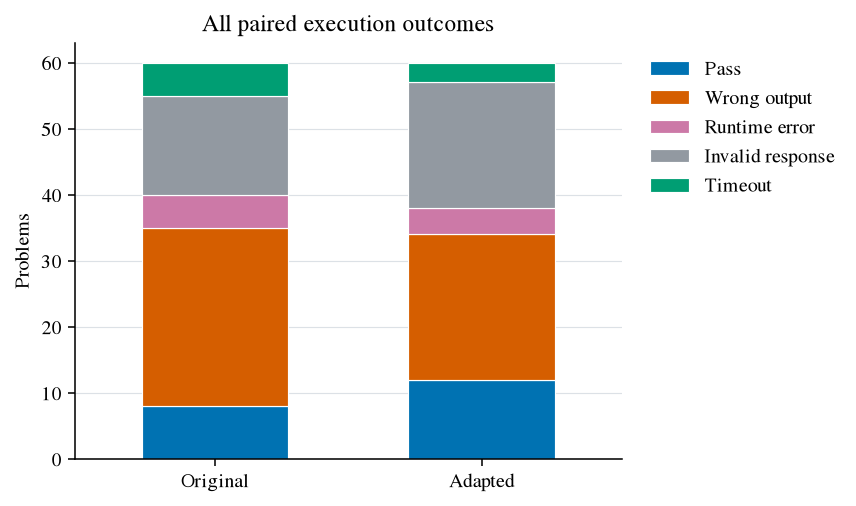

,Completed,Attempts,Median completed tokens,Cap hits
Original,45.0,60.0,389.0,15.0
Adapted,41.0,60.0,436.0,19.0


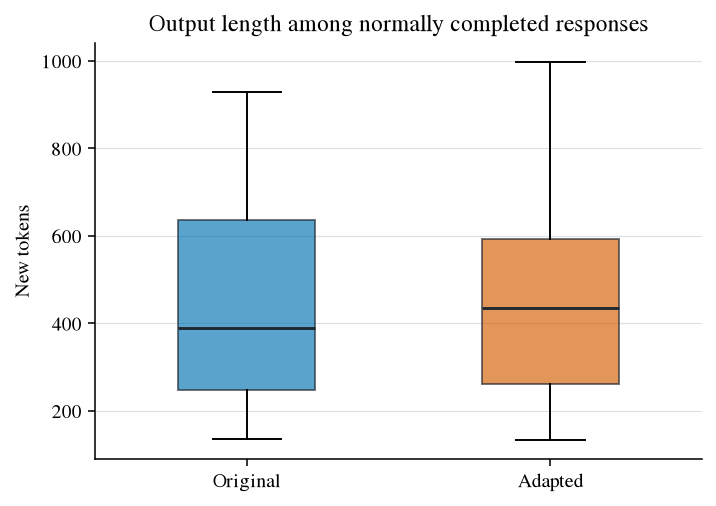

In [5]:
def paired_outcomes(pairs):
    p = pairs.dropna(subset=['original_0','adapted']).copy()
    p = p[~p[['original_0','adapted']].eq('infrastructure_error').any(axis=1)]
    p['before'], p['after'] = p.original_0.eq('pass'), p.adapted.eq('pass')
    return p

paired = paired_outcomes(pairs)
display(pd.crosstab(paired.before.rename('Original pass'),paired.after.rename('Adapted pass')))
display(paired.loc[paired.before.ne(paired.after),['problem','source','original_0','adapted']])
both = paired[['original_0','adapted']].ne('invalid_response').all(axis=1)
display(paired.groupby('source').agg(Problems=('problem','size'),Original=('before','sum'),Adapted=('after','sum')))
print(f'Both produced code: {paired.loc[both,"before"].sum()} -> {paired.loc[both,"after"].sum()} passes over {both.sum()} problems.')
wins, losses = int((~paired.before & paired.after).sum()), int((paired.before & ~paired.after).sum())
flips = wins+losses
print(f'Exact paired p = {min(1,2*sum(comb(flips,k) for k in range(min(wins,losses)+1))/2**flips):.3f}')

outcomes = paired[['original_0','adapted']].apply(pd.Series.value_counts).fillna(0).astype(int)
paper_style = {
    'font.family': 'serif',
    'font.serif': ['STIXGeneral'],
    'mathtext.fontset': 'stix',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'grid.color': '#DCE1E6',
    'grid.linewidth': 0.6,
    'axes.axisbelow': True,
    'figure.dpi': 140,
}
outcome_colors = {
    'pass': '#0072B2',
    'wrong_output': '#D55E00',
    'runtime_error': '#CC79A7',
    'invalid_response': '#9299A1',
    'timeout': '#009E73',
}
outcome_order = [key for key in outcome_colors if key in outcomes.index]
outcome_order += [key for key in outcomes.index if key not in outcome_colors]
plot_counts = outcomes.loc[outcome_order].T.rename(
    index={'original_0': 'Original', 'adapted': 'Adapted'}
)
plot_counts.columns = [label.replace('_', ' ').capitalize() for label in outcome_order]
with plt.rc_context(paper_style):
    fig, ax = plt.subplots(figsize=(6, 3.5), layout='constrained')
    plot_counts.plot.bar(
        ax=ax, stacked=True, rot=0, width=0.55,
        color=[outcome_colors.get(key, '#756BB1') for key in outcome_order],
        edgecolor='white', linewidth=0.6,
    )
    ax.set(title='All paired execution outcomes', ylabel='Problems')
    ax.grid(axis='y')
    ax.legend(frameon=False, loc='upper left', bbox_to_anchor=(1.02, 1))
    plt.show()

def heldout_lengths(data, pairs):
    keys = pairs.problem.astype(str)
    original = data[data.id.isin(keys+'-0')]
    adapted = data[data.id.isin(keys+'-adapted')]
    return {'Original':original,'Adapted':adapted}

outputs = heldout_lengths(data,paired)
lengths = {label:g.loc[g.complete,'output_tokens'] for label,g in outputs.items()}
display(pd.DataFrame({label:{'Completed':len(lengths[label]),'Attempts':len(g),
                            'Median completed tokens':lengths[label].median(),
                            'Cap hits':int((~g.complete & ~g.timed_out).sum())}
                      for label,g in outputs.items()}).T)
with plt.rc_context(paper_style):
    fig, ax = plt.subplots(figsize=(5, 3.5), layout='constrained')
    boxes = ax.boxplot(
        list(lengths.values()), patch_artist=True, widths=0.45,
        medianprops={'color': '#202932', 'linewidth': 1.5},
        flierprops={'marker': 'o', 'markersize': 3, 'markerfacecolor': 'none'},
    )
    for box, color in zip(boxes['boxes'], ['#0072B2', '#D55E00']):
        box.set(facecolor=color, edgecolor='#202932', alpha=0.65)
    ax.set_xticks([1, 2], list(lengths))
    ax.set(title='Output length among normally completed responses', ylabel='New tokens')
    ax.grid(axis='y')
    plt.show()


### Interpretation

The adapted model passed four more held-out problems. The judge picked the passing program in four of five pairs with exactly one pass. The small number of changed outcomes and the absence of a matched random-selection adapter limit attribution of the gain to the judge.